# Лабораторна робота № 10
## Основи роботи в Jupyter Notebook
**Варіант № 10 — Норвегія; подання натурального числа у вигляді суми квадратів двох натуральних чисел.**

**Мета:** опанувати створення блокнотів Jupyter, форматування Markdown/HTML, використання SVG та розробку функцій Python із перевіркою введених даних.

> Матеріал містить реальні результати виконання комірок Python у цьому блокноті. Дані про країну наведено за зазначеними джерелами.

# 1. Країна за варіантом: **Норвегія**

<div style="border:2px solid #16375c;border-radius:12px;padding:18px;background:#f1f7fa;">
<h2 style="color:#ba0c2f;">Королівство Норвегія</h2>
<p><b>Норвегія</b> — держава Північної Європи на Скандинавському півострові. Столиця — <b>Осло</b>. Державний устрій — <i>конституційна монархія</i>; законодавчу владу здійснює парламент Стортинг.</p>
<p style="color:#00205b;"><b>Ключова особливість:</b> поєднання гірських ландшафтів, фіордів і давніх культурних традицій.</p>
</div>

### Основні відомості

| Показник | Значення |
|:--|:--|
| Столиця | Осло |
| Форма державного правління | Конституційна монархія |
| Територія (за даними ООН, материкова площа та прилеглі території у визначенні джерела) | 323 772 км² |
| Чисельність населення, кінець II кварталу 2026 р. | **5 636 904 осіб** |
| Грошова одиниця | Норвезька крона (NOK) |
| Державна мова | Норвезька (букмол і нюношк як письмові норми) |

### Визначні пам'ятки

- **Природні об'єкти:**
  - Гейрангер-фіорд — один із відомих фіордів західної Норвегії;
  - Нерей-фіорд — частина об'єкта Світової спадщини ЮНЕСКО «Західнонорвезькі фіорди».
- **Культурна спадщина:**
  - історичний район Брюгген у Бергені;
  - гірниче містечко Рерус.
- **Відомі діячі:**
  - Едвард Ґріґ — композитор;
  - Генрік Ібсен — драматург;
  - Фрітьйоф Нансен — дослідник і гуманітарний діяч.

**Джерела:** [Статистика Норвегії](https://www.ssb.no/en/befolkning/folketall/statistikk/befolkning), [ООН](https://data.un.org/legacy/en/iso/no.html), [уряд Норвегії](https://www.regjeringen.no/en/the-government/id443314/), [пам'ятки ЮНЕСКО](https://www.visitnorway.com/places-to-go/unesco-world-heritage-sites/).

### 1.1. Прапор Норвегії (векторне зображення SVG)

Наведений нижче прапор **намальовано безпосередньо за допомогою HTML-тегу `<svg>`**, як вимагає завдання.

<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 22 16" width="330" height="240" role="img" aria-label="Прапор Норвегії"><rect width="22" height="16" fill="#BA0C2F"/><path d="M0 8h22M8 0v16" stroke="white" stroke-width="4"/><path d="M0 8h22M8 0v16" stroke="#00205B" stroke-width="2"/></svg>

### 1.2. Ілюстрації та посилання

**Вбудована ілюстрація фіордів (авторська стилізована схема):**

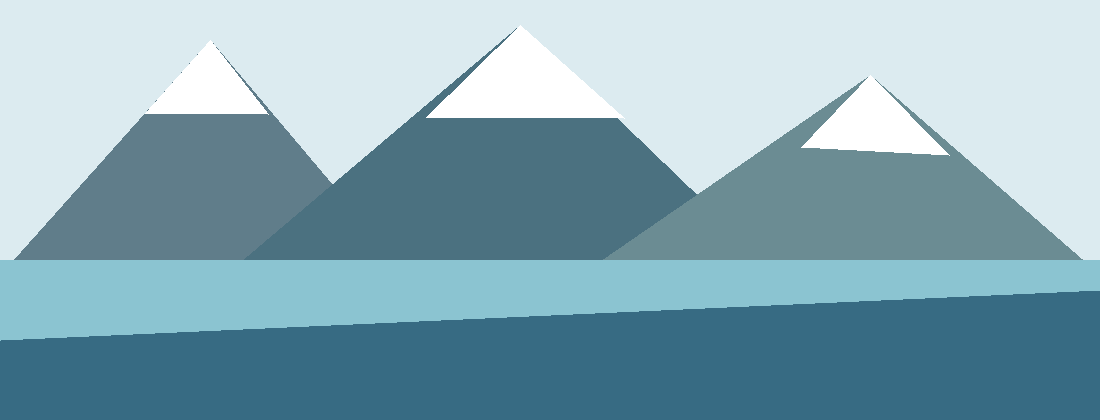

**Зображення за зовнішнім посиланням:**

![Прапор Норвегії, зовнішній ресурс](https://upload.wikimedia.org/wikipedia/commons/d/d9/Flag_of_Norway.svg)

Докладніше: [офіційний туристичний портал Норвегії](https://www.visitnorway.com/).

# 2. Алгоритмічне завдання (варіант 10)

**Постановка:** для введеного натурального числа `N` знайти натуральні числа `a` та `b`, для яких `a² + b² = N`. Якщо пари немає, вивести відповідне повідомлення. Обидва числа повинні бути **додатними** (нуль не допускається).

**Метод:** перебір `a` від 1 до `⌊√(N/2)⌋` із перевіркою, чи є `N−a²` точним квадратом цілого додатного числа. Це дозволяє знайти пару `a ≤ b` та уникнути повторів симетричних варіантів.

In [1]:
from math import isqrt

def sum_of_two_squares(n):
    """Знайти додатні цілі a,b: a²+b²=n; повернути (a,b) або None."""
    if isinstance(n, bool) or not isinstance(n, int):
        raise TypeError("N має бути цілим числом.")
    if n <= 0:
        raise ValueError("N має бути натуральним числом (N > 0).")
    for a in range(1, isqrt(n // 2) + 1):
        b_squared = n - a * a
        b = isqrt(b_squared)
        if b >= a and b * b == b_squared:
            return a, b
    return None

def task_10(n):
    pair = sum_of_two_squares(n)
    if pair is None:
        return f"Число {n} неможливо подати як суму квадратів двох натуральних чисел."
    a, b = pair
    return f"{a}² + {b}² = {n}"


### 2.1. Тестові приклади

Тести охоплюють випадок існування розв'язку, випадок його відсутності та іншу коректну комбінацію. Окремо перевірено обробку помилкового введення.

In [2]:
for n in (45, 21, 50):
    print(f"N = {n}: {task_10(n)}")


N = 45: 3² + 6² = 45
N = 21: Число 21 неможливо подати як суму квадратів двох натуральних чисел.
N = 50: 1² + 7² = 50


In [3]:
for invalid in (0, -4, 5.5, "45"):
    try:
        print(task_10(invalid))
    except (TypeError, ValueError) as exc:
        print(f"N = {invalid!r}: помилка — {exc}")

N = 0: помилка — N має бути натуральним числом (N > 0).
N = -4: помилка — N має бути натуральним числом (N > 0).
N = 5.5: помилка — N має бути цілим числом.
N = '45': помилка — N має бути цілим числом.


### 2.2. Перевірка правильності

Виконується автоматична перевірка рівності `a²+b²=N` для знайдених пар і коректної відсутності рішення в прикладі `N=21`.

In [4]:
assert sum_of_two_squares(45) == (3, 6)
assert sum_of_two_squares(21) is None
assert sum_of_two_squares(50) == (1, 7)
assert all(sum_of_two_squares(n) is None or sum(x*x for x in sum_of_two_squares(n)) == n
           for n in range(1, 300))
print("Перевірки виконано успішно.")

Перевірки виконано успішно.


# 3. Діаграма активності алгоритму

Діаграма в окремому файлі `LR10_activity.png` відображає логіку введення і перевірки `N`, пошук пар та виведення відповіді. Нижче наведено діаграму активності алгоритму:

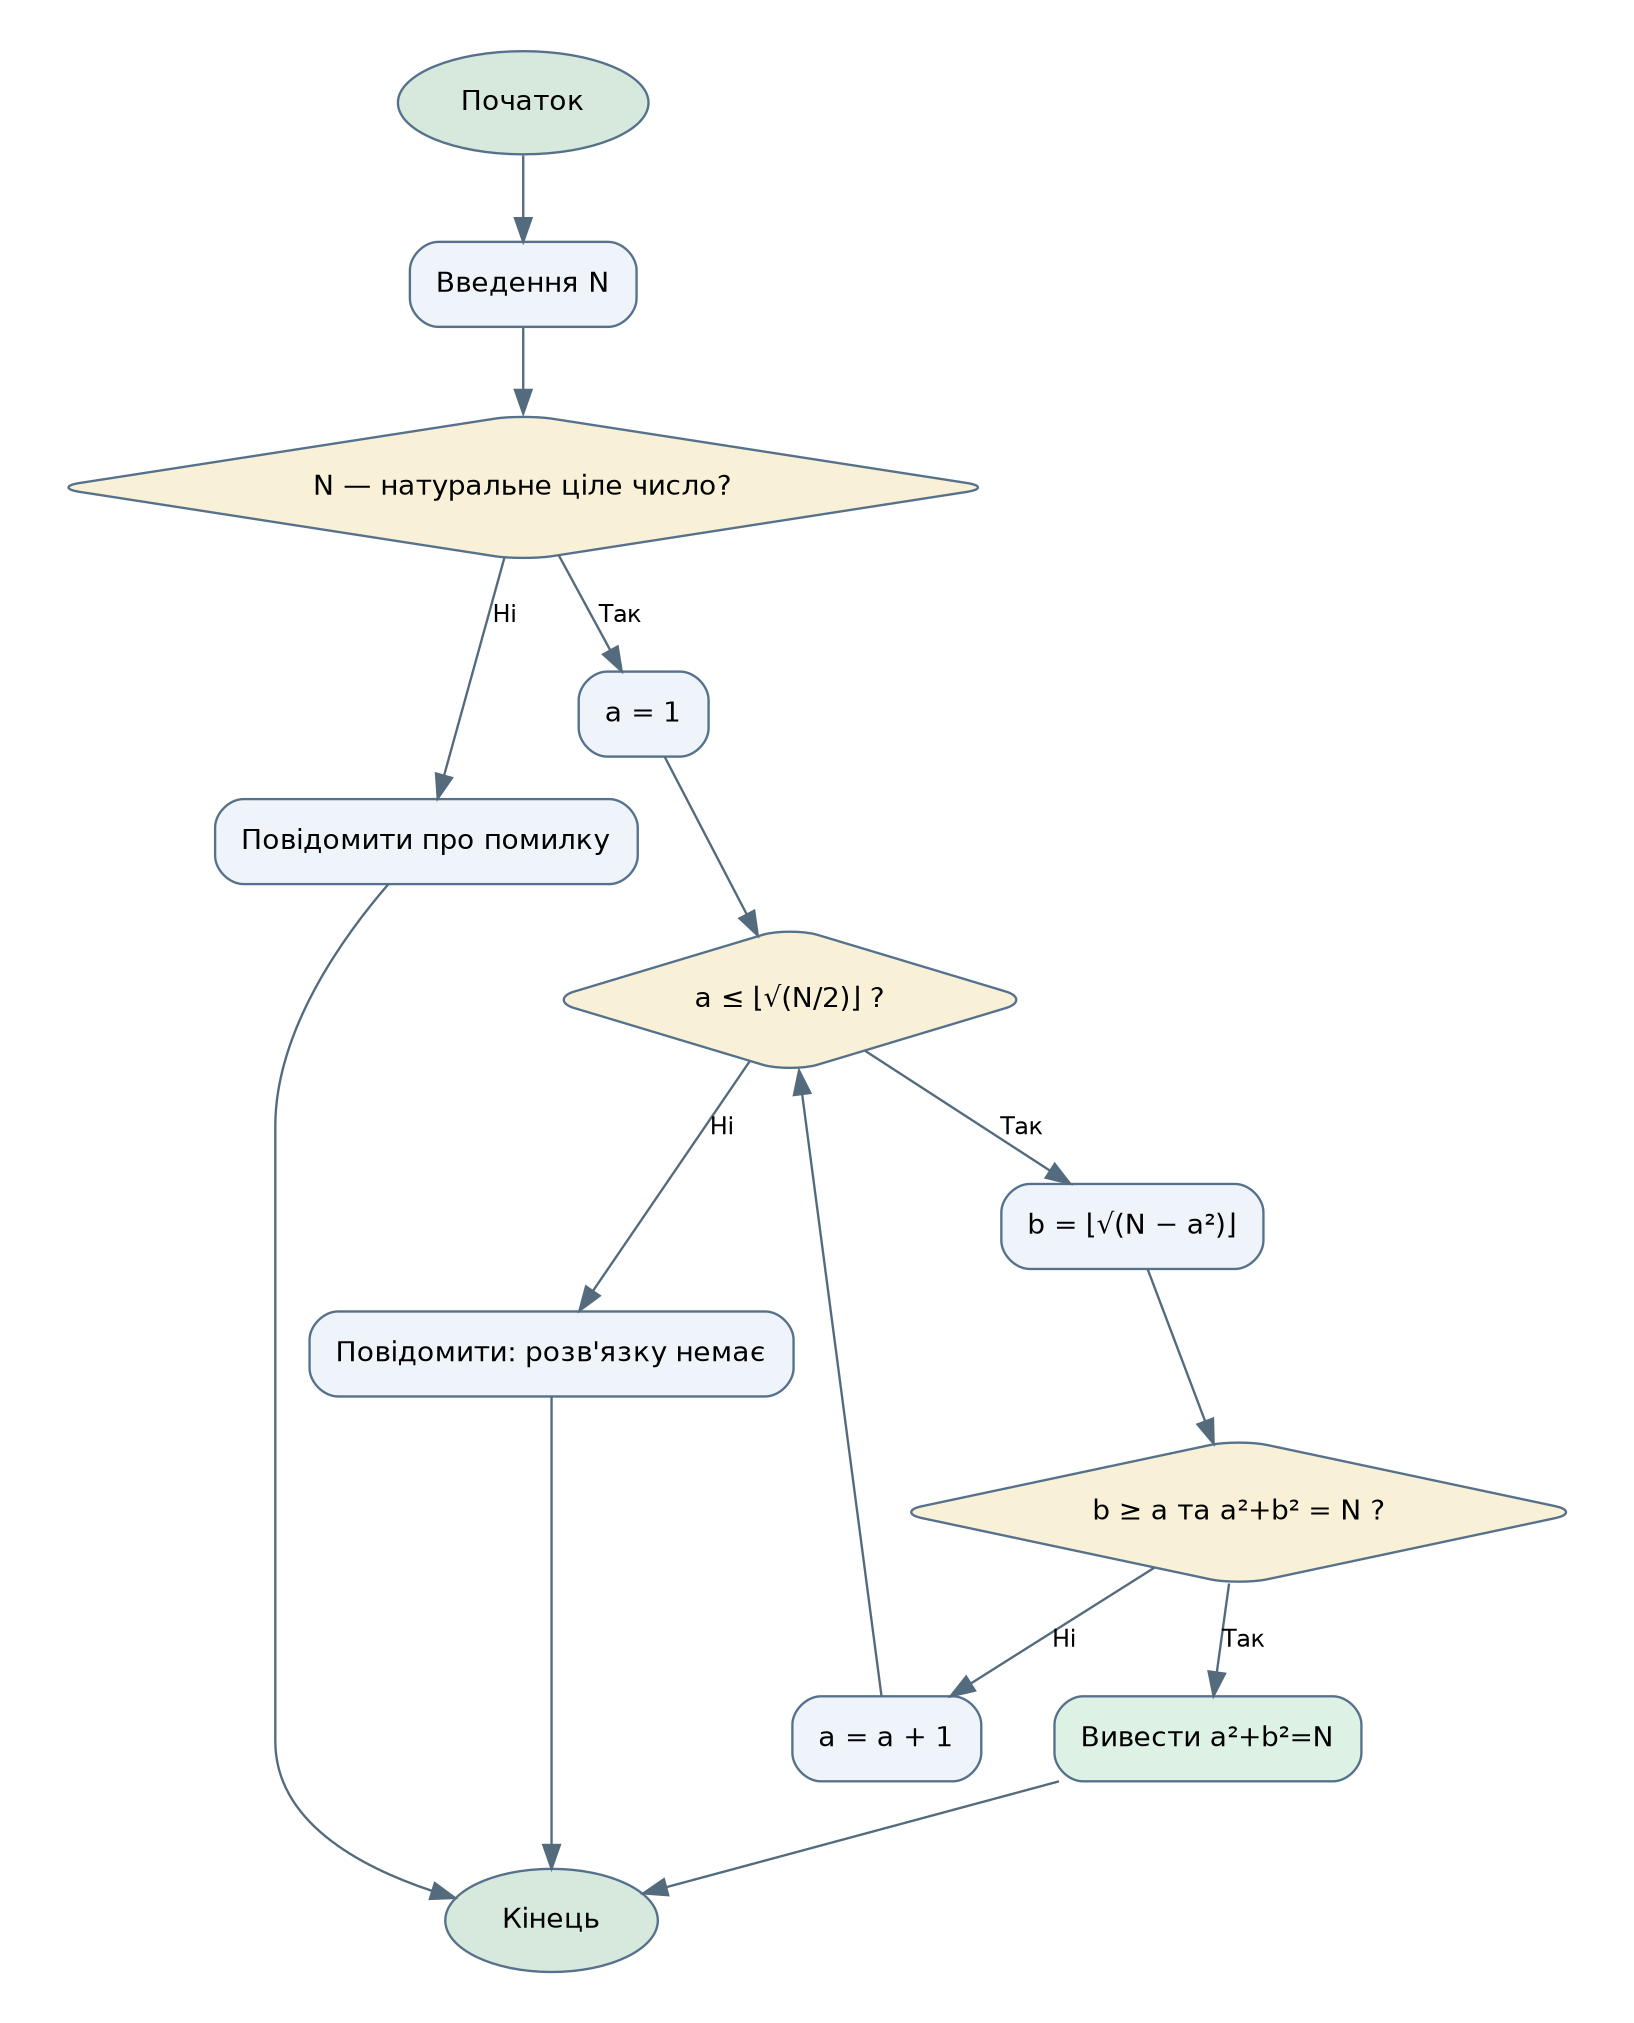

Алгоритмічний зміст:

1. Перевірка типу та натуральності `N`.
2. Початкове значення `a = 1`.
3. Повторюваний пошук `b = isqrt(N − a²)`.
4. Якщо `a² + b² = N`, повернути пару; інакше збільшити `a`.
5. Якщо всі варіанти перевірено, повідомити про відсутність розв’язку.

# Висновок

У роботі сформовано блокнот Jupyter з текстовими та кодовими комірками, форматуванням Markdown і HTML, таблицею, вкладеними списками, гіперпосиланнями, вбудованим зображенням і векторним прапором Норвегії. Розроблено функцію Python для пошуку подання натурального числа сумою квадратів двох додатних цілих чисел. Проведено тестування та перевірку некоректних вхідних значень.

# Використана література

1. Методичні матеріали до лабораторної роботи № 10 «Основи роботи в Jupyter Notebook».
2. [Project Jupyter](https://jupyter.org/).
3. [Jupyter Notebook Documentation](https://jupyter-notebook.readthedocs.io/).
4. [Markdown Guide](https://www.markdownguide.org/basic-syntax/).
5. [Statistics Norway](https://www.ssb.no/en/befolkning/folketall/statistikk/befolkning).
6. [UN Data — Norway](https://data.un.org/legacy/en/iso/no.html).
7. [Visit Norway — UNESCO](https://www.visitnorway.com/places-to-go/unesco-world-heritage-sites/).